In [1]:
# TODO: kontrola interpolacji w ROI
# TODO: liczymi ICA i korelujemy z EOG
# TODO: sprawdzenie pętli 1 do 60
# TODO: dlaczego mamy różne liczby epok
# TODO: usuwanie zaszunionych kanałów

# EEG Preprocessing Pipeline

## Overview
This notebook implements a comprehensive EEG preprocessing pipeline using MNE-Python. It processes raw EEG data through multiple stages including filtering, bad channel detection, artifact removal, and epoch extraction.

## Pipeline Steps

1. **Data Loading** - Loads raw EEG files and behavioral/trigger data
2. **Montage Setup** - Configures electrode positions and channel types (EEG, EOG)
3. **Trigger Processing** - Converts triggers to annotations and removes training periods
4. **Signal Cropping** - Trims data to relevant time windows around events
5. **Filtering** - Applies bandpass filter to remove noise and drifts
6. **Bad Channel Detection** - Identifies noisy channels using PyPREP (with optional RANSAC)
7. **Re-referencing** - Sets average reference across all EEG channels
8. **Ocular Artifact Removal** - Removes eye movement artifacts using EOG regression
9. **Channel Interpolation** - Interpolates previously identified bad channels
10. **Epoching** - Segments continuous data into event-locked epochs
11. **Automatic Artifact Rejection** - Uses AutoReject to identify and repair/reject bad epochs

## Key Dependencies

- **MNE-Python** - Core EEG processing library
- **PyPREP** - Bad channel detection
- **AutoReject** - Automated epoch rejection and repair
- **pandas** - Trigger file handling

## Configuration Parameters

All preprocessing parameters are defined in the Configuration section and can be adjusted:
- File paths (input/output directories)
- Electrode montage type
- Filter cutoffs
- Epoch time windows
- AutoReject hyperparameters
- Output options (saving, plotting)

## Output

Preprocessed epochs are saved as FIF files with metadata (participant ID, sex, age) in the filename.

In [2]:
%pip install pyprep numpy pandas autoreject mne

  Obtaining dependency information for pyprep from https://files.pythonhosted.org/packages/ea/e1/5c43b1e72756f1692fd018e6e236d5fd73625a262ac0cb1ddcf367995797/pyprep-0.9.0-py3-none-any.whl.metadata
  Obtaining dependency information for autoreject from https://files.pythonhosted.org/packages/c1/37/e7e2758d4dc5d11d168ed69655e9ed4497b5d9146073a36c4c386fa74ec5/autoreject-0.5.1-py3-none-any.whl.metadata
  Obtaining dependency information for mne from https://files.pythonhosted.org/packages/44/e4/face21e5da320fdc3a3e016ea93a28d1b786d01b36d75872627161a837aa/mne-1.13.2-py3-none-any.whl.metadata
  Obtaining dependency information for scipy>=1.6.3 from https://files.pythonhosted.org/packages/a5/f6/a5b82f8abbe14d134691b8b903696f701d25a081353a29dc655c364d9e62/scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.2 MB/s eta 0:00:00a 0:00:01
  Obtaining dependency information for joblib>=1.3.2 from https://files.pythonhosted.org/packages

In [1]:
import mne
from mne.preprocessing import EOGRegression
from tqdm import tqdm
from pyprep.find_noisy_channels import NoisyChannels
import os
import sys
import numpy as np
import pandas as pd
from autoreject import AutoReject

from src.load_data import prepare_files_info
from src.utils import write
from src.triggers import set_annotations_from_trigger_file, drop_training_annotations
from src.epochs import create_epochs

# matplotlib.use('TkAgg')
mne.set_log_level('ERROR')

### Configuration

In [2]:
# Paths to data folders
BEH_PATH = "BEH" # Path to the folder with behavioral data files.
EEG_PATH = "EEG" # Path to the folder with raw EEG data files.
RESULT_PATH = "PREPROCESSED" # Path to the folder where preprocessed data will be saved.

# Electrode montage settings
MONTAGE = "biosemi64" # Name of the EEG electrode montage used in the recording (e.g., "biosemi64").

# Signal cropping settings
START_CUT_EXTRA_TIME = 2 # Extra time (in seconds) kept before the first event/trigger.
END_CUT_EXTRA_TIME = 2 # Extra time (in seconds) kept after the last event/trigger.

# Filtering settings
LOW_PASS = 0.5 # High‑pass filter cutoff frequency in Hz (removes very slow drifts).
HIGH_PASS = 48 # Low‑pass filter cutoff frequency in Hz (removes high‑frequency noise).

# Bad channel detection (PyPREP)
RANSAC = True # Whether to use the RANSAC algorithm for robust bad channel detection.
SEED = 42 # Random seed to ensure reproducible results.

# Epoching settings
EPOCHS_LEN = [0, 30] # Epoch time window [tmin, tmax] in seconds relative to event onset.
TRIGGER_TYPE = "show_task" # Type/name of triggers used to create epochs.

# AutoReject settings (automatic artifact rejection for epochs)
INTERPOLATION = [1, 2, 3, 4] # Number of channels to interpolate when repairing bad epochs.
CONSENSUS = None # Consensus percentage for rejecting epochs (None = let AutoReject choose).
METHOD = 'bayesian_optimization' # Strategy for optimizing rejection thresholds.
N_JOBS = 1 # Number of parallel jobs used by AutoReject.
CV = 10 # Number of cross‑validation folds used by AutoReject.

# Output and visualization settings
SAVE_DATA = True # If True, save preprocessed epochs to disk as FIF files.
OVERWRITE_DATA = True
WRITE_INFO = True # If True, print textual progress and summary information.
PLOT_INFO = True # If True, show diagnostic plots (e.g., rejected epochs, reject_log).

### Parameters

In [3]:
DATA = prepare_files_info(eeg_path=EEG_PATH, beh_path=BEH_PATH)

 - no beh file


### Preprocessing

IZ2310 ma dodatkowy stan 65284 na początku pliku, którego nie ma w pozostałych czterech plikach. U pozostałych osób wartość 130816 lub 130820 występuje na początku przez około sekundę, a potem pojawia się wartość bazowa 65280. U IZ2310 po 130820 pojawia się jeszcze 65284 przez 2292 próbki, czyli około 2,24 s.
To wyjaśnia dodatkowy trigger 4 w IZ2310. Nie powinniśmy jednak usuwać wszystkich kodów 4 — późniejsze wystąpienia są prawidłowymi triggerami.
\
\
Proponowana poprawka
Najbezpieczniej odrzucać zdarzenia na podstawie zgodności sekwencji z CSV, a nie numeru triggera. Możemy zastosować następującą logikę:
1. Wykryć zdarzenia przez mne.find_events() z consecutive=True i min_duration=2 / raw.info["sfreq"].
2. Odfiltrować kody spoza zakresu 65281–65340.
3. Porównać wykryte kody z trigg_df["trigger_no"].
4. Jeśli sekwencje się różnią, sprawdzić, czy na początku występuje dodatkowe zdarzenie przed pierwszym triggerem z CSV.
5. Usunąć je tylko wtedy, gdy potwierdzimy, że nie należy do eksperymentu. W przeciwnym razie przerwać przetwarzanie i zgłosić błąd.
\
\
Dla IZ2310 oczekiwana sekwencja zaczyna się od triggera 1, natomiast MNE zwraca najpierw 4, a dopiero potem 1 .To pasuje do dodatkowego stanu początkowego. Pozostałe cztery pliki mają już zgodne sekwencje.

In [10]:
import importlib
import src.triggers

importlib.reload(src.triggers)

from src.triggers import (
    set_annotations_from_trigger_file,
    drop_training_annotations,
)

  0%|          | 0/5 [00:00<?, ?it/s]

IZ2310
ERROR: Trigger count mismatch: EEG=176, CSV=175. Participant skipped.


 20%|██        | 1/5 [00:01<00:06,  1.60s/it]

JA0310
EEG triggers validated: 173; annotations created: 173.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


bad channels: [np.str_('PO7'), 'Iz', 'P9', 'P7', 'PO3', np.str_('PO8')]
interpolated 6 channels
Szukany trigger: 'show_task'
Liczba dopasowanych triggerów: 42
Przykłady: ['experiment_show_task_10_R4.png_0', 'experiment_show_task_12_R6.png_1', 'experiment_show_task_13_R2.png_0', 'experiment_show_task_14_R1.png_1', 'experiment_show_task_15_R2.png_1']
Created 42 epochs (30.000 s) for 'show_task'


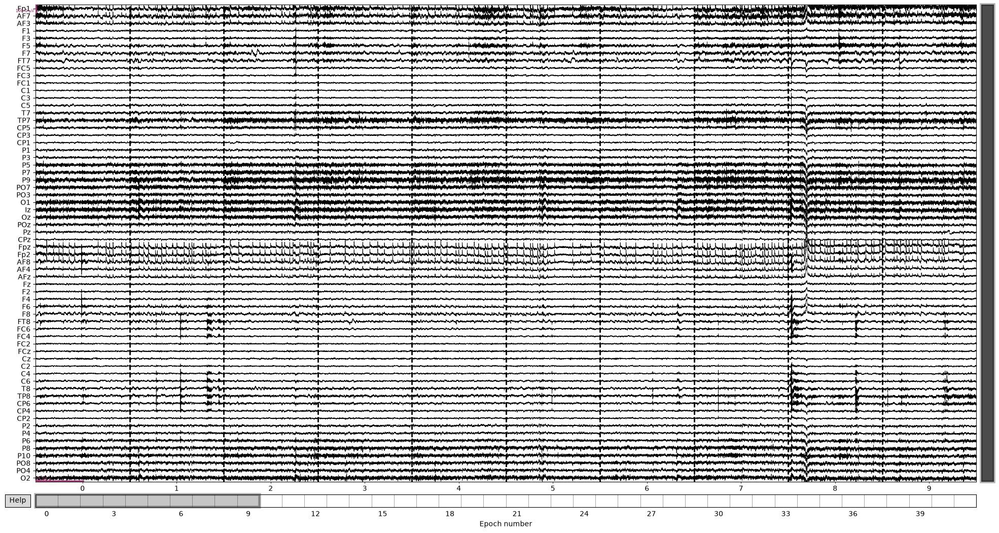

Number of epochs: 41
Number of rejected epochs: 1


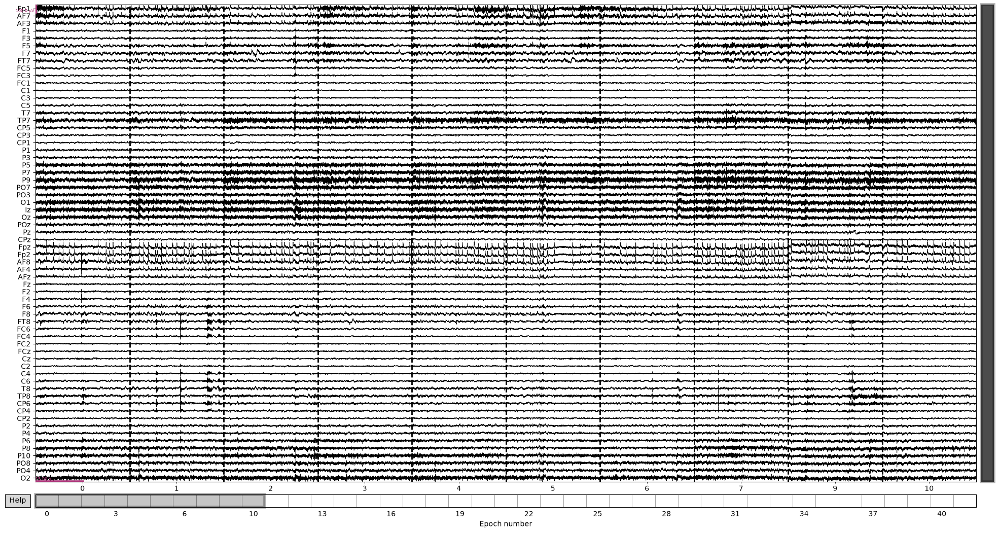

bad epochs


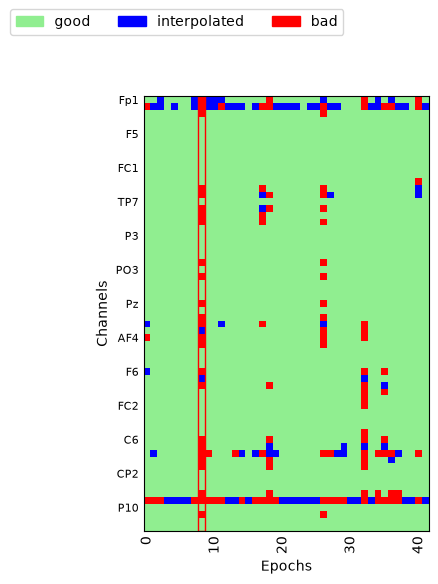

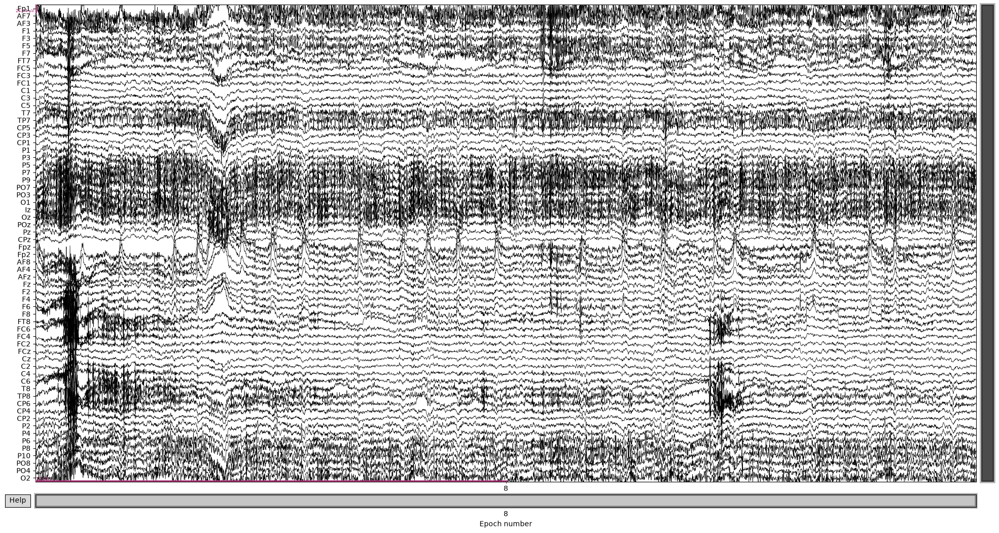

Data saved to PREPROCESSED/JA0310_F_20_preprocessed-epo.fif


 40%|████      | 2/5 [04:37<08:08, 162.98s/it]

JB0612
EEG triggers validated: 176; annotations created: 176.
bad channels: ['Pz', 'P1', np.str_('POz'), 'P9']
interpolated 4 channels
Szukany trigger: 'show_task'
Liczba dopasowanych triggerów: 42
Przykłady: ['experiment_show_task_10_R4.png_1', 'experiment_show_task_12_R6.png_1', 'experiment_show_task_13_R2.png_1', 'experiment_show_task_14_R1.png_1', 'experiment_show_task_15_R2.png_1']
Created 42 epochs (30.000 s) for 'show_task'


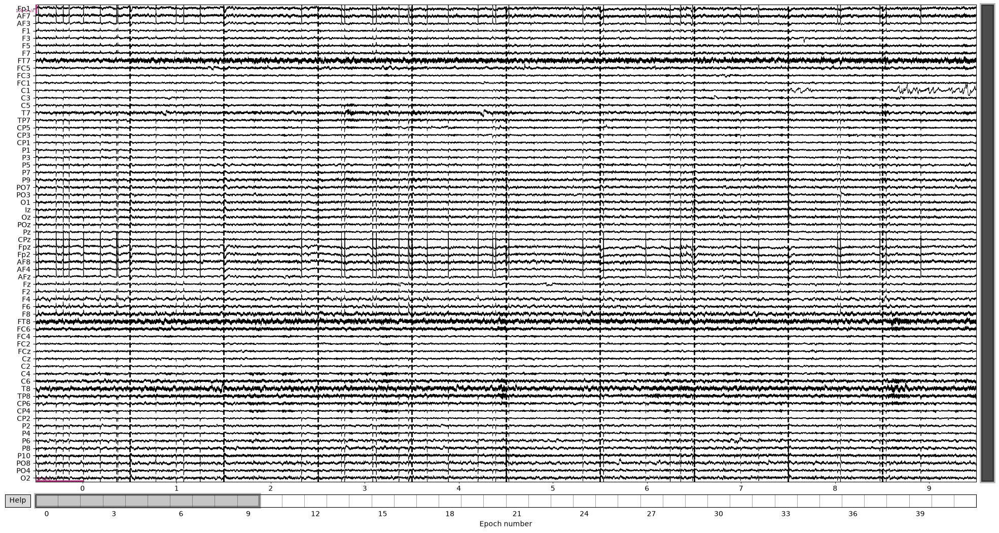

Number of epochs: 42
Number of rejected epochs: 0


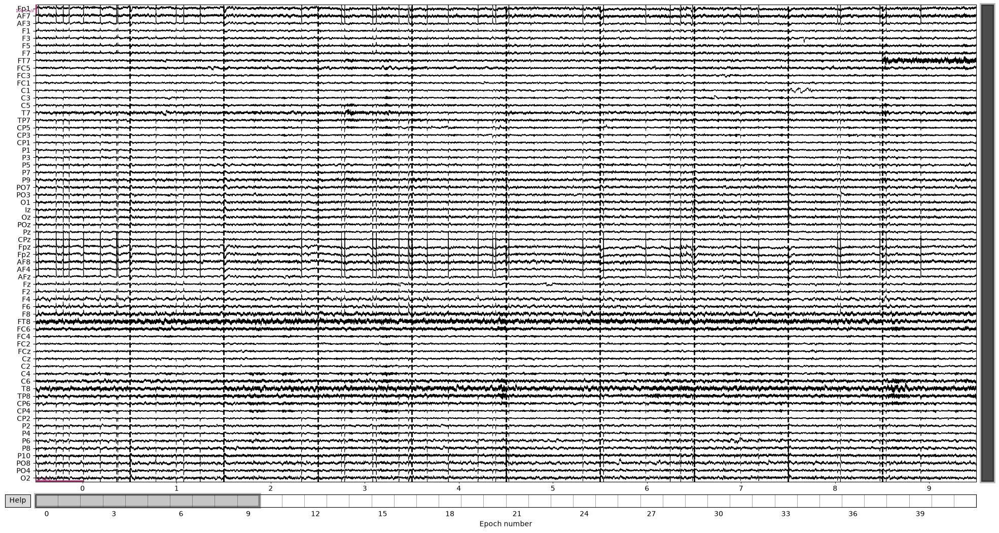

bad epochs


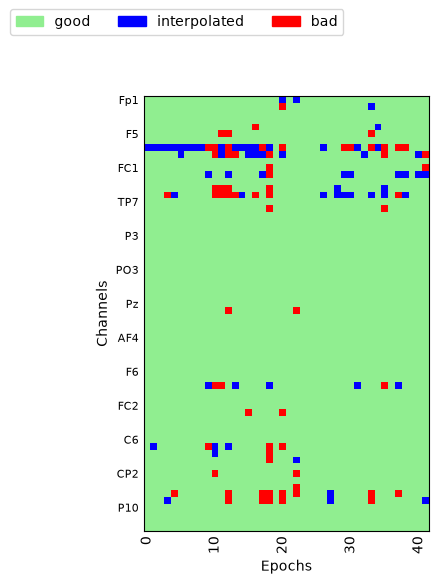

Data saved to PREPROCESSED/JB0612_F_20_preprocessed-epo.fif


 60%|██████    | 3/5 [08:40<06:38, 199.44s/it]

HP1505
EEG triggers validated: 176; annotations created: 176.
bad channels: [np.str_('POz'), 'Iz', 'Oz', 'PO3', 'O2']
interpolated 5 channels
Szukany trigger: 'show_task'
Liczba dopasowanych triggerów: 42
Przykłady: ['experiment_show_task_10_R4.png_1', 'experiment_show_task_12_R6.png_1', 'experiment_show_task_13_R2.png_1', 'experiment_show_task_14_R1.png_1', 'experiment_show_task_15_R2.png_1']
Created 42 epochs (30.000 s) for 'show_task'


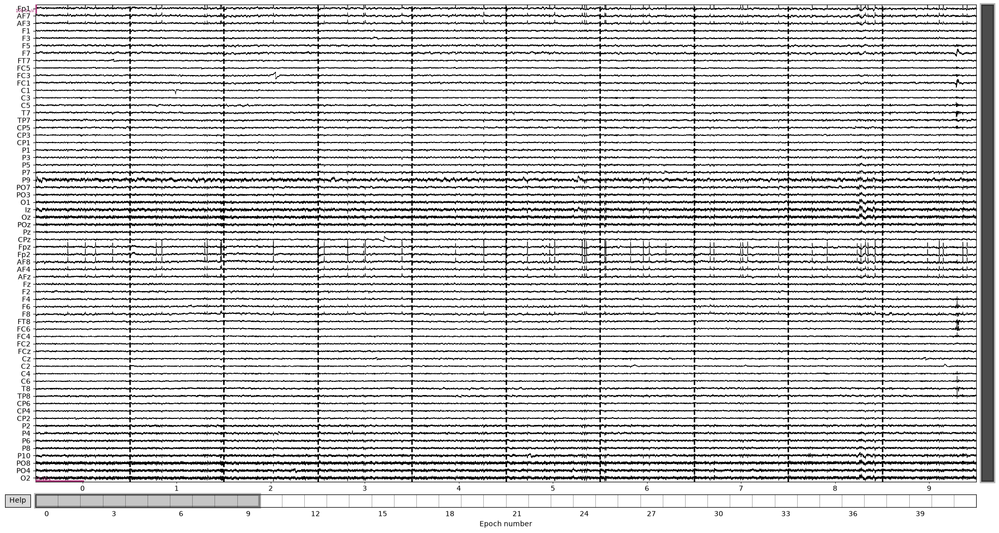

Number of epochs: 41
Number of rejected epochs: 1


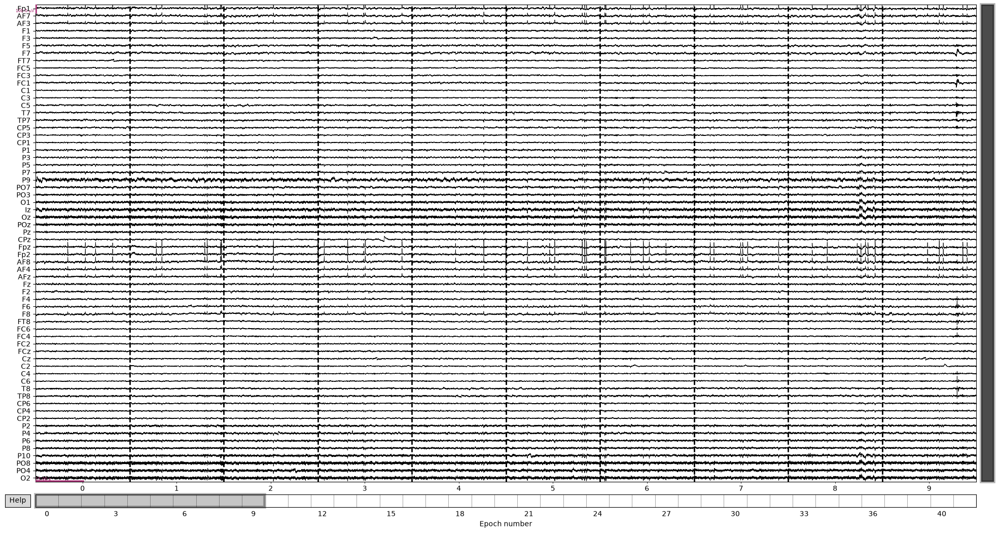

bad epochs


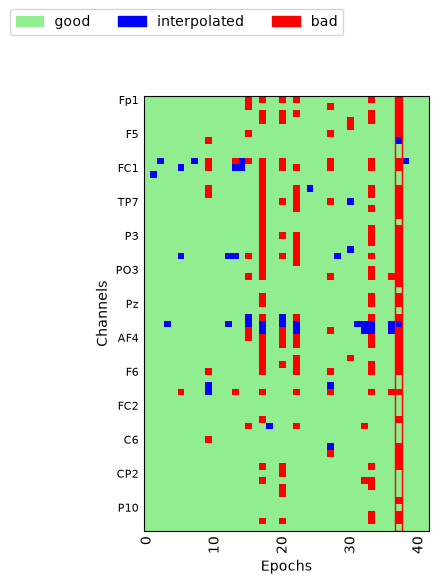

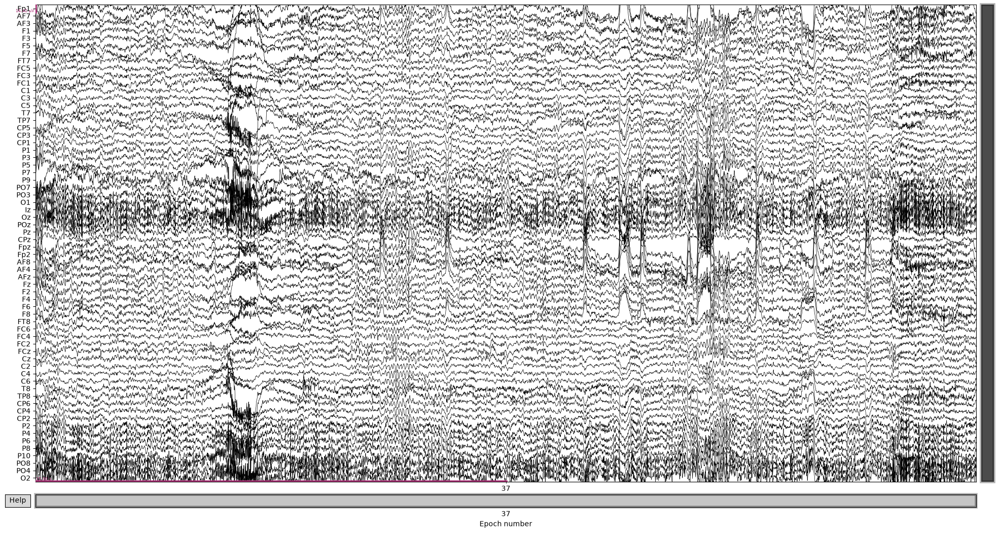

Data saved to PREPROCESSED/HP1505_M_23_preprocessed-epo.fif


 80%|████████  | 4/5 [13:02<03:44, 224.38s/it]

HZ1304
EEG triggers validated: 175; annotations created: 175.
bad channels: ['P2', 'P1', 'Fp1', 'PO3', np.str_('P3')]
interpolated 5 channels
Szukany trigger: 'show_task'
Liczba dopasowanych triggerów: 42
Przykłady: ['experiment_show_task_10_R4.png_1', 'experiment_show_task_12_R6.png_1', 'experiment_show_task_13_R2.png_0', 'experiment_show_task_14_R1.png_1', 'experiment_show_task_15_R2.png_1']
Created 42 epochs (30.000 s) for 'show_task'


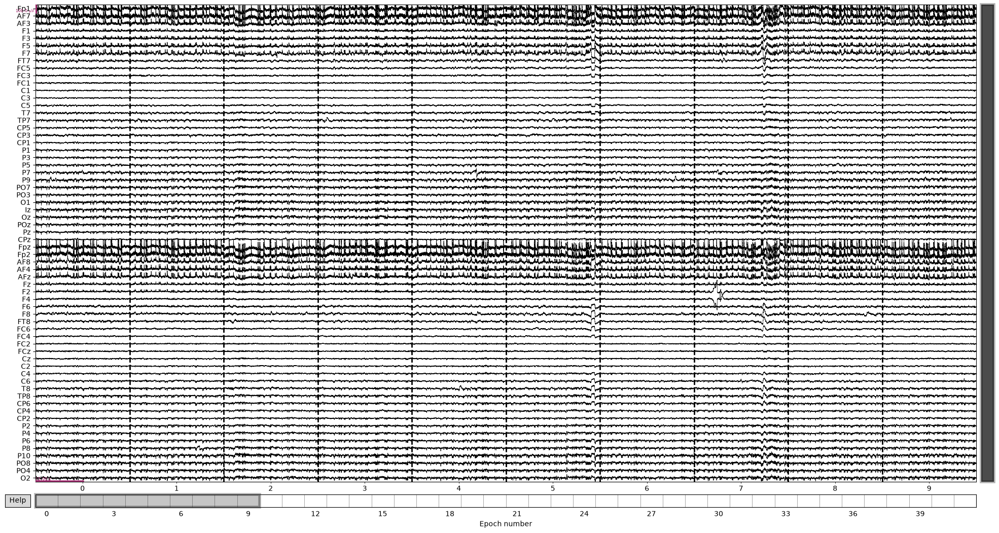

Number of epochs: 40
Number of rejected epochs: 2


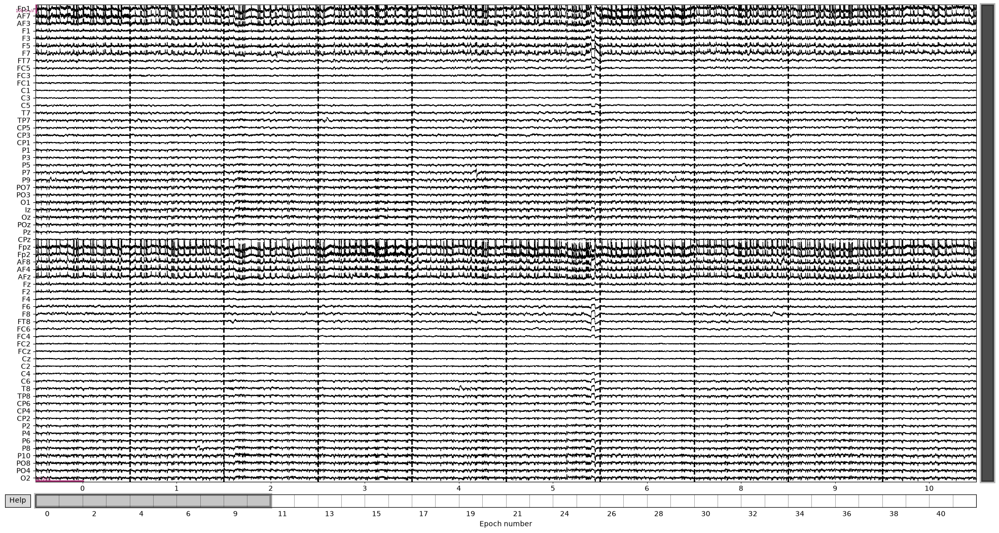

bad epochs


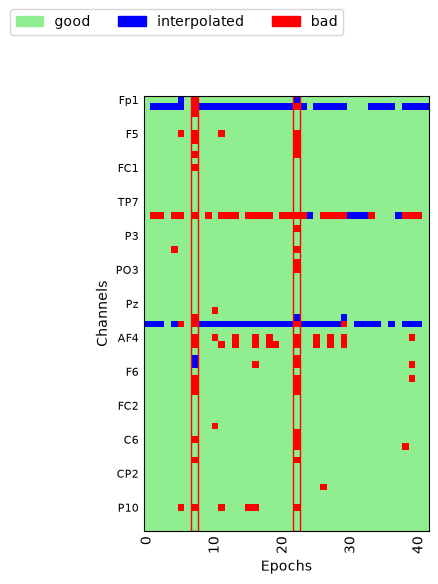

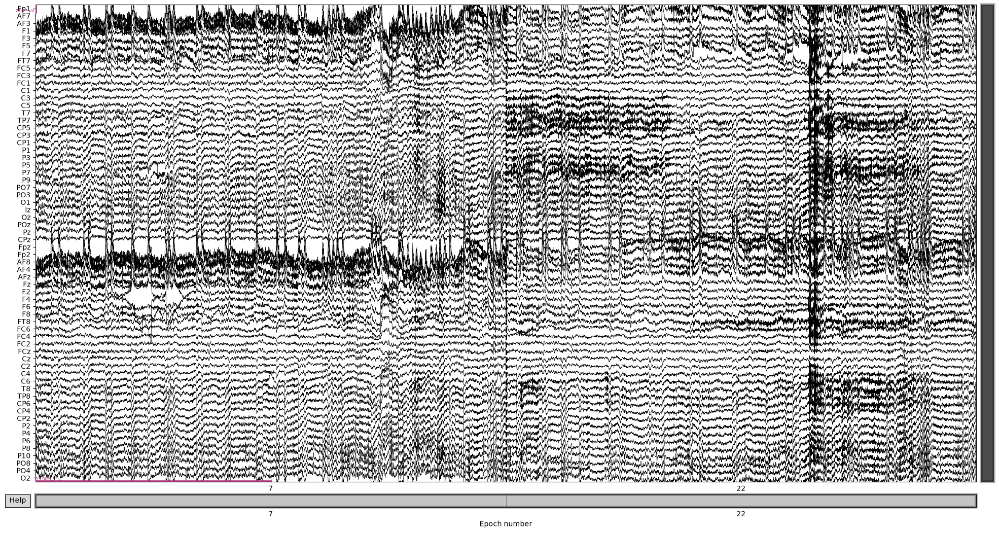

Data saved to PREPROCESSED/HZ1304_F_29_preprocessed-epo.fif


100%|██████████| 5/5 [17:19<00:00, 207.91s/it]


In [4]:
for part in tqdm(DATA):
    write(part['ID'], WRITE_INFO)
    file_name = f"{part['ID']}_{part['sex']}_{part['age']}_preprocessed-epo.fif"
    if not OVERWRITE_DATA and file_name in os.listdir(RESULT_PATH):
        write("File already exists", WRITE_INFO)
        continue
    # --- load eeg ---
    raw = mne.io.read_raw(part['eeg_file'], preload=True, verbose=False)
    trigg_df = pd.read_csv(part['trigg_file'], comment='#')

    # --- montage ---
    eog_channels = {f'EXG{i}': 'eog' for i in range(1, 5) if f'EXG{i}' in raw.ch_names}
    if eog_channels:
        raw.set_channel_types(eog_channels)
    drop_channels = [f'EXG{i}' for i in range(5, 9) if f'EXG{i}' in raw.ch_names]
    if drop_channels:
        raw.drop_channels(drop_channels)
    raw.set_montage(MONTAGE, on_missing='warn')

    # --- change triggers to annotation and rename them
    raw = set_annotations_from_trigger_file(raw, trigg_df, write_info=WRITE_INFO)
    
    if raw is None:
        sys.stdout.flush() # for correct order of printed text when using tqdm
        continue

    # --- remove training ---
    raw = drop_training_annotations(raw)

    # --- crop signal ---
    times = raw.annotations.onset
    start_cut = max(0, times[0] - START_CUT_EXTRA_TIME)
    end_cut = min(raw.times[-1], times[-1] + END_CUT_EXTRA_TIME)
    raw.crop(start_cut, end_cut)
    #raw.annotations.onset -= start_cut

    # --- filter ---
    raw.filter(l_freq=LOW_PASS, h_freq=HIGH_PASS, picks="eeg", verbose=False)

    # --- find and mark bad channels ---
    nc = NoisyChannels(raw, ransac=RANSAC, do_detrend=False, random_state=SEED)
    nc.find_all_bads()
    raw.info['bads'] = nc.get_bads()
    write(f"bad channels: {raw.info['bads']}", WRITE_INFO)

    # --- set reference ---
    raw.set_eeg_reference("average", verbose=False)

    # --- remove ocular artifacts ---
    model_plain = EOGRegression(picks="eeg", exclude="bads", picks_artifact="eog").fit(raw)
    raw = model_plain.apply(raw, copy=True)

    # --- interpolate bad channels ---
    if len(raw.info['bads']) > 0:
        raw.interpolate_bads(reset_bads=True, verbose=False)
        write(f"interpolated {len(nc.get_bads())} channels", WRITE_INFO)
    
    # --- create epochs ---
    epochs_all = create_epochs(raw, trigger_type=TRIGGER_TYPE, tmin=EPOCHS_LEN[0],
                               tmax=EPOCHS_LEN[1], write_info=WRITE_INFO)
    
    if epochs_all is None:
        continue
    
    epochs = epochs_all.copy()

    # --- Plot EEG before AutoReject ---
    if PLOT_INFO:
        epochs.plot(
            n_epochs=10,
            n_channels=len(epochs.ch_names),
            scalings=dict(eeg=50e-6),
            title=f"EEG after preprocessing — {part['ID']}",
        )

    epochs_original = epochs.copy()

        # --- remove epochs with artifacts ---
    ar = AutoReject(
            n_interpolate=[2],
            consensus=CONSENSUS,
            thresh_method=METHOD,
            n_jobs=N_JOBS,
            cv = CV,
            random_state=SEED,
            verbose=False)

    epochs, reject_log = ar.fit_transform(epochs, return_log=True)
    
    write(f"Number of epochs: {len(epochs)}", WRITE_INFO)
    write(f"Number of rejected epochs: {reject_log.bad_epochs.sum()}", WRITE_INFO)
    
    if PLOT_INFO:
            epochs.plot(
                n_epochs=10,
                n_channels=len(epochs.ch_names),
                scalings=dict(eeg=50e-6),
                title=f"EEG after AR — {part['ID']}",
            )

    # --- Plot removed epochs ---
    if PLOT_INFO:
        print("bad epochs")
        reject_log.plot('horizontal')
        bad_epochs_idx = np.where(reject_log.bad_epochs)[0] # Bad epoch index
        
        if 0 < len(bad_epochs_idx) < 20:
                epochs_original[bad_epochs_idx].plot(
                    n_epochs=len(bad_epochs_idx),
                    n_channels=64,
                    scalings='auto',
                    title='Removed epochs')

        # --- Save data ---
    if SAVE_DATA:
        result_dir = f"{RESULT_PATH}"
        os.makedirs(result_dir, exist_ok=True)

        output_file = os.path.join(result_dir, file_name)
        epochs.save(output_file, verbose=False, overwrite=True)

        write(f"Data saved to {output_file}", WRITE_INFO)

        sys.stdout.flush() # for correct order of printed text when using tqdm


In [11]:
import matplotlib.pyplot as plt 

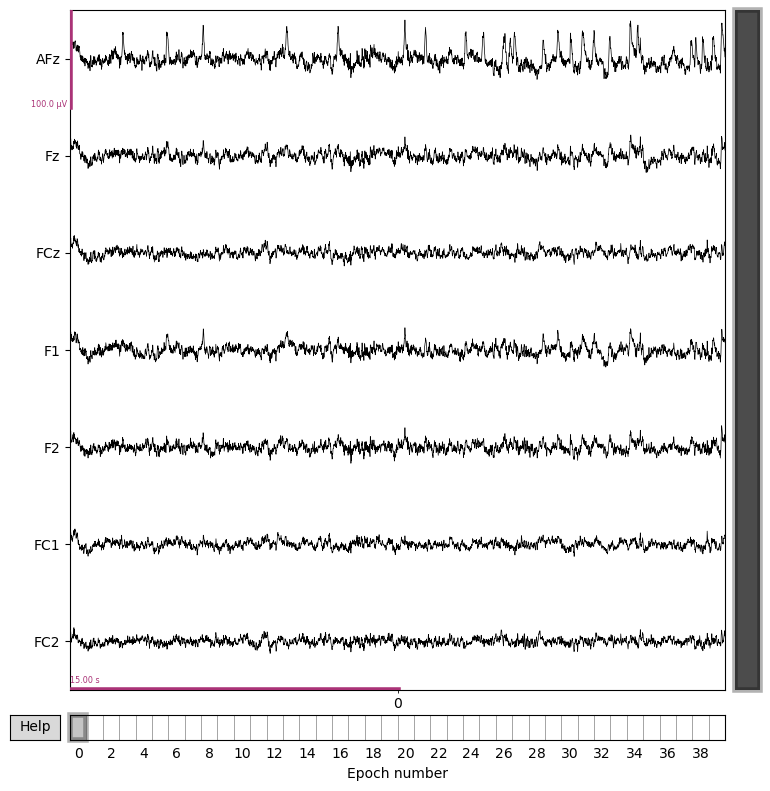

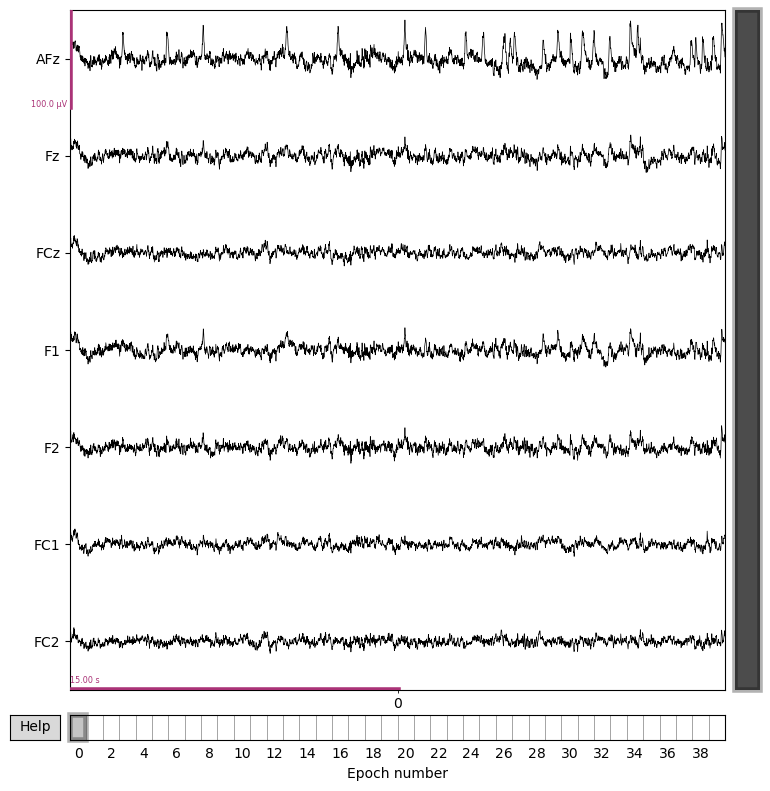

In [27]:
file_path = r"PREPROCESSED_frontal/AM0108_F_20_preprocessed-epo.fif"
epochs_clean = mne.read_epochs(
    r"PREPROCESSED_frontal/AM0108_F_20_preprocessed-epo.fif",
    preload=True,
    verbose=False
)

epochs_clean.plot(
    n_epochs=min(1, 10),
    n_channels=len(epochs_clean.ch_names),
    scalings={"eeg": 50e-6}
)